#Exploratory Data Analysis Report

##Step 1: Verifying Samples and Clinical Data
Since the clinical data (like ER status, relapse status, lymph node status) is being pulled from the GEO Omnibus, it must be converted into a format that is machine readable. When downloading from the source, it downloads as a txt. This section below formats the txt into a dataframe. It also renames some of the key column headers, so that they will match the other data files.
### Results Review
The expression matrix, ABS detection, P-value detection and clinical parameters dataset do not have any missing information. <br>
The annotation dataset has some missing values. the most important to note for this project are:


*   Gene Title
*   Gene Symbol



In [1]:
import os

print("Current working directory:", os.getcwd())
print("Files in current directory:", os.listdir())

Current working directory: c:\Users\Sara\Documents\CIND820\gse2034-research-dashboard\analysis
Files in current directory: ['EDA Report.ipynb']


In [ ]:
'''Converting Clinical Data txt file into dataframe'''
import pandas as pd
import matplotlib.pyplot as plt
clinical_data = pd.read_csv('../data/clinical_data.txt', sep="\t")
#print (clinical_data)
clinical_parameters_df = pd.DataFrame(clinical_data)
'''renaming the column names to avoid any special character issues down the line'''
clinical_parameters_df.rename(columns={"GEO asscession number":"Sample_Accession", 
                                       "time to relapse or last follow-up (months)":"Follow_up_months", 
                                       "relapse (1=True)":"Relapse", "ER Status":"ER_status"},inplace=True)
print (clinical_parameters_df)
print ('\nCount of NaN in each column:\n', clinical_parameters_df.isnull().sum())

     PID Sample_Accession lymph node status  Follow_up_months  Relapse  \
0      3         GSM36793          negative               101        0   
1      5         GSM36796          negative               118        0   
2      6         GSM36797          negative                 9        1   
3      7         GSM36798          negative               106        0   
4      8         GSM36800          negative                37        1   
..   ...              ...               ...               ...      ...   
281  900         GSM36887          negative               108        0   
282  901         GSM36889          negative               108        0   
283  903         GSM36892          negative               110        0   
284  909         GSM36894          negative               109        0   
285  913         GSM36911          negative                80        1   

    ER_status  Brain relapses (1=yes, 0=no)  
0         ER-                             0  
1         ER+      

In [ ]:
#time_col = "time to relapse or last follow-up (months)"

#print(clinical_parameters_df[[
   # "Sample_Accession",
   # "Relapse",
   # time_col
#]].head(10))

#print("\nMissing values:")
#print(clinical_parameters_df[time_col].isnull().sum())

#print("\nSummary statistics:")
#print(clinical_parameters_df[time_col].describe())

  Sample_Accession  Relapse  time to relapse or last follow-up (months)
0         GSM36793        0                                         101
1         GSM36796        0                                         118
2         GSM36797        1                                           9
3         GSM36798        0                                         106
4         GSM36800        1                                          37
5         GSM36801        0                                         125
6         GSM36834        0                                         109
7         GSM36835        1                                          14
8         GSM36836        0                                          99
9         GSM36837        0                                         137

Missing values:
0

Summary statistics:
count    286.000000
mean      77.520979
std       42.267958
min        2.000000
25%       37.000000
50%       86.000000
75%      108.000000
max      171.000000
Name: ti

## Validating how the Kaggle Dataset is normalized (plot twist, it is the same values as the GEO omnibus)

In [4]:
'''Checking to see if the GEO Omnbibus is the same as the Kaggle. Importing the Geo Omnbinus and sorting it by ID_Ref so that this dataframe and the kaggle one can be properly compared'''

geo_gene = pd.read_csv('../data/GSE2034_series_matrix.txt', sep="\t")
descending_geo_gene_df = pd.DataFrame(geo_gene)
geo_gene_df = descending_geo_gene_df.sort_values(by='ID_REF', ascending=False, ignore_index=True)
#print (geo_gene_df)

geo_gene_df.head(10)
#print ('\nCount of NaN in each column:\n', geo_gene_df.isnull().sum())


,ID_REF,GSM36777,GSM36778,GSM36779,GSM36780,GSM36781,GSM36782,GSM36783,GSM36784,GSM36785,...,GSM37053,GSM37054,GSM37055,GSM37056,GSM37057,GSM37058,GSM37059,GSM37060,GSM37061,GSM37062
0,AFFX-r2-P1-cre-5_at,25644.4,40720.0,50878.7,46870.8,40847.1,38321.7,38065.4,61162.1,22337.5,...,115944.2,66109.4,68767.8,49943.9,56631.2,43122.0,39033.8,58585.2,38360.8,30222.1
1,AFFX-r2-P1-cre-3_at,33168.9,54401.4,61244.1,62292.1,57295.1,50074.6,46900.9,78481.5,29587.9,...,146868.8,85468.0,87049.5,62343.2,70987.3,57830.1,50140.4,69320.3,48495.6,38260.2
2,AFFX-r2-Hs28SrRNA-M_at,661.5,716.1,1189.3,801.1,191.1,257.2,117.8,411.1,246.4,...,826.8,321.4,882.5,429.5,740.4,444.5,330.3,532.4,188.0,642.4
3,AFFX-r2-Hs28SrRNA-5_at,619.9,511.3,1618.4,780.5,276.0,277.8,251.1,489.4,311.5,...,1736.3,479.3,1223.0,602.3,713.5,346.6,538.9,425.5,247.5,648.3
4,AFFX-r2-Hs28SrRNA-3_at,1920.8,725.2,4172.0,1881.9,435.8,703.4,393.6,850.1,533.4,...,3724.6,917.1,3250.3,487.1,822.7,842.8,619.6,1113.8,498.8,1105.5
5,AFFX-r2-Hs18SrRNA-M_x_at,737.5,822.2,2724.6,757.8,114.3,237.5,239.6,368.7,227.4,...,1400.2,271.5,1516.4,656.0,715.2,302.4,429.1,456.1,274.0,758.3
6,AFFX-r2-Hs18SrRNA-5_at,1093.1,467.9,3118.9,664.8,27.2,187.9,113.4,374.4,124.2,...,1293.8,253.6,1126.5,286.2,607.6,361.6,231.1,322.5,136.7,547.0
7,AFFX-r2-Hs18SrRNA-3_s_at,1192.4,1010.5,3567.7,1582.9,420.1,568.1,348.6,954.3,536.0,...,2886.8,906.7,2170.3,1242.3,1156.7,813.9,682.1,1091.1,258.0,1188.9
8,AFFX-r2-Ec-bioD-5_at,5865.6,9912.1,13108.1,9052.7,9722.1,10466.5,10771.4,15028.7,6278.4,...,35946.6,18063.0,22226.3,12449.5,16209.5,12475.0,10182.5,14860.8,10492.6,7278.3
9,AFFX-r2-Ec-bioD-3_at,6289.8,11238.1,12469.8,9050.9,8562.3,10090.0,9569.2,12521.8,5830.4,...,30129.7,17034.5,20820.7,11789.4,16696.2,12107.7,10330.5,15805.0,9545.9,7032.6


In [5]:
'''Convert Expression Matrix into Dataframe'''

gene_seq_data = pd.read_csv('../data/GSE2034_family_expression_matrix.csv', sep=",")
non_log_gene_seq_df = pd.DataFrame(gene_seq_data)
as_gene_seq_df = non_log_gene_seq_df.sort_values(by='ID_REF', ascending=False, ignore_index=True)
#print (as_gene_seq_df)
as_gene_seq_df.head(10)
#print ('\nCount of NaN in each column:\n', gene_seq_df.isnull().sum())

,ID_REF,GSM36777,GSM36778,GSM36779,GSM36780,GSM36781,GSM36782,GSM36783,GSM36784,GSM36785,...,GSM37053,GSM37054,GSM37055,GSM37056,GSM37057,GSM37058,GSM37059,GSM37060,GSM37061,GSM37062
0,AFFX-r2-P1-cre-5_at,25644.4,40720.0,50878.7,46870.8,40847.1,38321.7,38065.4,61162.1,22337.5,...,115944.2,66109.4,68767.8,49943.9,56631.2,43122.0,39033.8,58585.2,38360.8,30222.1
1,AFFX-r2-P1-cre-3_at,33168.9,54401.4,61244.1,62292.1,57295.1,50074.6,46900.9,78481.5,29587.9,...,146868.8,85468.0,87049.5,62343.2,70987.3,57830.1,50140.4,69320.3,48495.6,38260.2
2,AFFX-r2-Hs28SrRNA-M_at,661.5,716.1,1189.3,801.1,191.1,257.2,117.8,411.1,246.4,...,826.8,321.4,882.5,429.5,740.4,444.5,330.3,532.4,188.0,642.4
3,AFFX-r2-Hs28SrRNA-5_at,619.9,511.3,1618.4,780.5,276.0,277.8,251.1,489.4,311.5,...,1736.3,479.3,1223.0,602.3,713.5,346.6,538.9,425.5,247.5,648.3
4,AFFX-r2-Hs28SrRNA-3_at,1920.8,725.2,4172.0,1881.9,435.8,703.4,393.6,850.1,533.4,...,3724.6,917.1,3250.3,487.1,822.7,842.8,619.6,1113.8,498.8,1105.5
5,AFFX-r2-Hs18SrRNA-M_x_at,737.5,822.2,2724.6,757.8,114.3,237.5,239.6,368.7,227.4,...,1400.2,271.5,1516.4,656.0,715.2,302.4,429.1,456.1,274.0,758.3
6,AFFX-r2-Hs18SrRNA-5_at,1093.1,467.9,3118.9,664.8,27.2,187.9,113.4,374.4,124.2,...,1293.8,253.6,1126.5,286.2,607.6,361.6,231.1,322.5,136.7,547.0
7,AFFX-r2-Hs18SrRNA-3_s_at,1192.4,1010.5,3567.7,1582.9,420.1,568.1,348.6,954.3,536.0,...,2886.8,906.7,2170.3,1242.3,1156.7,813.9,682.1,1091.1,258.0,1188.9
8,AFFX-r2-Ec-bioD-5_at,5865.6,9912.1,13108.1,9052.7,9722.1,10466.5,10771.4,15028.7,6278.4,...,35946.6,18063.0,22226.3,12449.5,16209.5,12475.0,10182.5,14860.8,10492.6,7278.3
9,AFFX-r2-Ec-bioD-3_at,6289.8,11238.1,12469.8,9050.9,8562.3,10090.0,9569.2,12521.8,5830.4,...,30129.7,17034.5,20820.7,11789.4,16696.2,12107.7,10330.5,15805.0,9545.9,7032.6


In [6]:
as_gene_seq_df.equals(geo_gene_df)

True

In [7]:
'''Making a df without the ID_REF so we can check the distribution and also log just the numerical values'''
expression_df = non_log_gene_seq_df.iloc[:, 1:]

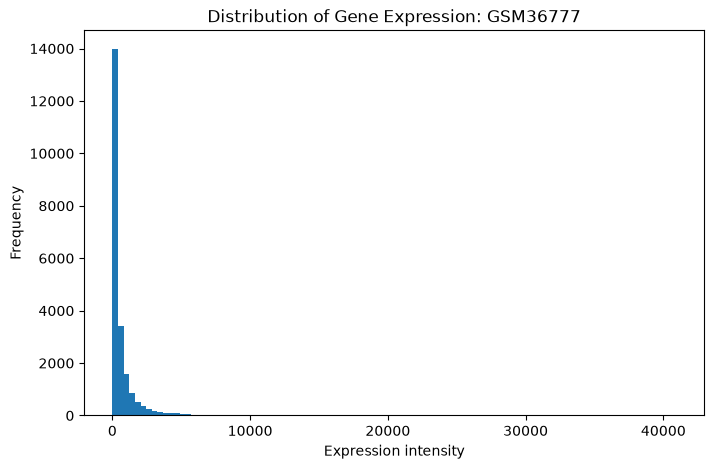

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(expression_df["GSM36777"], bins=100)
plt.xlabel("Expression intensity")
plt.ylabel("Frequency")
plt.title("Distribution of Gene Expression: GSM36777")
plt.show()

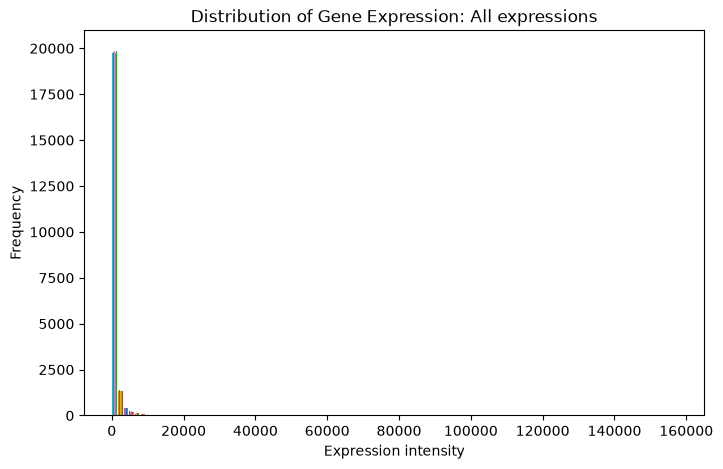

In [9]:
# All distribution, not logged

plt.figure(figsize=(8, 5))
plt.hist(expression_df, bins=100)
plt.xlabel("Expression intensity")
plt.ylabel("Frequency")
plt.title("Distribution of Gene Expression: All expressions")
plt.show()

In [10]:
import numpy as np

logged_gene_seq_df = np.log2(expression_df)

print(logged_gene_seq_df.describe())

           GSM36777      GSM36778      GSM36779      GSM36780      GSM36781  \
count  22283.000000  22283.000000  22283.000000  22283.000000  22283.000000   
mean       7.737938      7.975433      7.653201      7.862685      7.930087   
std        2.529003      2.308450      2.574607      2.437147      2.373104   
min       -1.000000     -0.321928     -1.736966     -1.321928     -0.321928   
25%        6.107478      6.467606      5.925999      6.280770      6.418696   
50%        7.883254      8.125155      7.754888      8.008989      8.076281   
75%        9.474416      9.457073      9.402586      9.456046      9.517079   
max       15.320416     16.063717     15.983753     16.532048     16.210222   

           GSM36782      GSM36783      GSM36784      GSM36785      GSM36786  \
count  22283.000000  22283.000000  22283.000000  22283.000000  22283.000000   
mean       7.840518      7.660660      7.968896      7.885976      7.748220   
std        2.456770      2.587130      2.353672    

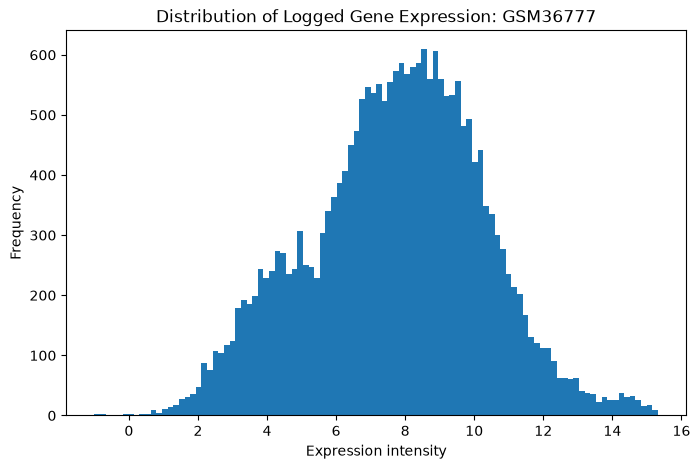

In [11]:
#Distribution of just 1 sample in log df
plt.figure(figsize=(8, 5))
plt.hist(logged_gene_seq_df["GSM36777"], bins=100)
plt.xlabel("Expression intensity")
plt.ylabel("Frequency")
plt.title("Distribution of Logged Gene Expression: GSM36777")
plt.show()

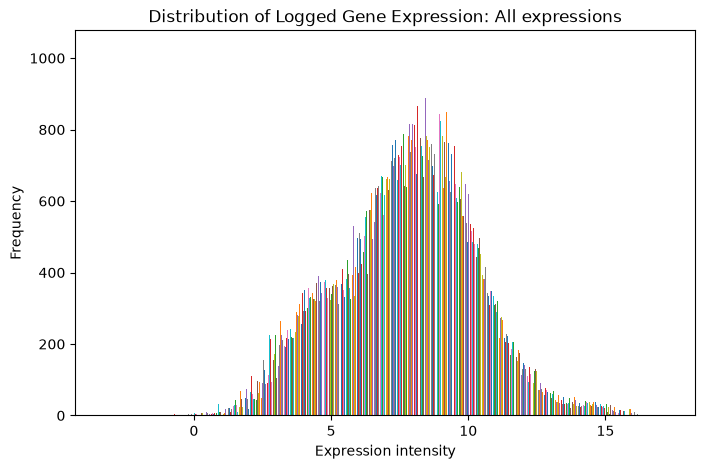

In [12]:
#Distribution of just 1 sample in log df
plt.figure(figsize=(8, 5))
plt.hist(logged_gene_seq_df, bins=100)
plt.xlabel("Expression intensity")
plt.ylabel("Frequency")
plt.title("Distribution of Logged Gene Expression: All expressions")
plt.show()

## Generating Logged sequence dataframe to use for the rest of the analysis and cleaning

In [13]:
'''Merging the dataset back together, putting the logged values along with the ID_REF because that had to be removed to log the numerical values'''
gene_seq_df = pd.concat(
    [
        non_log_gene_seq_df[["ID_REF"]],
        logged_gene_seq_df
    ],
    axis=1
)

print(gene_seq_df.shape)
print(gene_seq_df.columns[:5])
gene_seq_df.head(10)

(22283, 287)
Index(['ID_REF', 'GSM36777', 'GSM36778', 'GSM36779', 'GSM36780'], dtype='object')


,ID_REF,GSM36777,GSM36778,GSM36779,GSM36780,GSM36781,GSM36782,GSM36783,GSM36784,GSM36785,...,GSM37053,GSM37054,GSM37055,GSM37056,GSM37057,GSM37058,GSM37059,GSM37060,GSM37061,GSM37062
0,AFFX-BioB-5_at,8.869440,9.558421,9.938697,9.812498,9.511950,9.711667,9.563959,10.166540,8.315602,...,11.445015,10.605109,10.921841,10.174676,10.479780,10.094738,9.784635,10.196848,9.779883,9.445222
1,AFFX-BioB-M_at,9.845176,10.700266,11.032115,10.759722,10.636896,10.702086,10.745674,11.384406,9.528063,...,12.608578,12.135934,11.873867,10.930811,11.452035,11.076482,10.830911,11.234398,10.791000,9.869748
2,AFFX-BioB-3_at,8.871289,9.960436,10.007448,9.824641,9.315150,9.826390,9.748528,10.198077,8.702865,...,11.846979,10.607053,11.104599,9.930885,10.747857,10.054469,9.726899,10.464750,9.638617,9.241507
3,AFFX-BioC-5_at,10.421118,11.294104,11.398583,11.428831,11.075747,10.982566,10.867588,11.501887,10.454608,...,12.682139,11.713172,12.156652,11.531186,11.621228,11.271638,11.040427,11.513432,10.949316,10.916029
4,AFFX-BioC-3_at,10.033698,10.914908,10.922882,10.695402,10.710720,10.664714,10.847449,11.188960,9.946760,...,12.478997,11.534108,11.779842,11.018478,11.341130,10.930590,10.776680,11.199488,10.844784,10.376560
5,AFFX-BioDn-5_at,10.516389,11.228999,11.455533,11.146123,10.665247,11.192724,11.131986,11.689561,10.504024,...,13.052059,12.055452,12.344490,11.240672,11.873175,11.449045,11.188032,11.732507,11.196602,10.787576
6,AFFX-BioDn-3_at,12.921357,13.612592,13.798674,13.480879,13.449084,13.463780,13.358102,13.926370,12.764561,...,15.153813,14.251416,14.472494,13.766995,14.125454,13.674567,13.506432,14.026506,13.393042,13.264340
7,AFFX-CreX-5_at,13.713247,14.532009,14.843077,14.340789,14.244936,14.464527,14.371851,14.871568,13.710989,...,16.043014,15.103792,15.593948,14.821704,15.056320,14.754454,14.355028,15.070985,14.432738,13.978737
8,AFFX-CreX-3_at,14.244141,15.116791,15.365475,14.838835,14.727405,14.939405,14.809984,15.244379,14.189346,...,16.401256,15.512361,15.858928,15.306809,15.442247,15.091489,14.907088,15.538916,14.868089,14.512691
9,AFFX-DapX-5_at,2.459432,6.095924,5.031219,3.827819,5.593951,4.385431,5.354029,6.015694,5.791814,...,4.638074,5.395748,5.121015,6.078951,5.990955,2.405992,2.887525,5.744161,2.906891,5.984134


## Reviewing ABS and P value data for the signal intensity, and creating parameters to filter weak signals from the dataset

In [14]:
'''Convert ABS DETECTION data file into dataframe'''

PAM_data= pd.read_csv('../data/GSE2034_family_matrix_ABS_CALL.csv', sep=",")
PAM_data_df = pd.DataFrame(PAM_data)
print (PAM_data_df)

print ('\nCount of NaN in each column:\n', PAM_data_df.isnull().sum())

               ID_REF GSM36777 GSM36778 GSM36779 GSM36780 GSM36781 GSM36782  \
0      AFFX-BioB-5_at        P        P        P        P        P        P   
1      AFFX-BioB-M_at        P        P        P        P        P        P   
2      AFFX-BioB-3_at        P        P        P        P        P        P   
3      AFFX-BioC-5_at        P        P        P        P        P        P   
4      AFFX-BioC-3_at        P        P        P        P        P        P   
...               ...      ...      ...      ...      ...      ...      ...   
22278     222380_s_at        P        P        P        P        P        P   
22279       222381_at        A        A        A        A        A        A   
22280     222382_x_at        A        A        A        P        A        A   
22281     222383_s_at        A        A        A        A        A        A   
22282       222384_at        A        A        A        A        A        A   

      GSM36783 GSM36784 GSM36785  ... GSM37053 GSM3

In [15]:
'''Convert Detection P-value file into dataframe'''
P_data= pd.read_csv('../data/GSE2034_family_matrix_DETECTION_P_VALUE.csv', sep=",")
P_data_df = pd.DataFrame(P_data)
print (P_data_df)

print ('\nCount of NaN in each column:\n', P_data_df.isnull().sum())

               ID_REF  GSM36777  GSM36778  GSM36779  GSM36780  GSM36781  \
0      AFFX-BioB-5_at  0.002023  0.001248  0.000390  0.000972  0.001593   
1      AFFX-BioB-M_at  0.000081  0.000044  0.000044  0.000052  0.000095   
2      AFFX-BioB-3_at  0.000195  0.000052  0.000052  0.000060  0.000127   
3      AFFX-BioC-5_at  0.000127  0.000110  0.000081  0.000110  0.000195   
4      AFFX-BioC-3_at  0.000070  0.000081  0.000070  0.000070  0.000060   
...               ...       ...       ...       ...       ...       ...   
22278     222380_s_at  0.000732  0.000244  0.030273  0.000732  0.000732   
22279       222381_at  0.334473  0.219482  0.111572  0.111572  0.303711   
22280     222382_x_at  0.129639  0.303711  0.171387  0.030273  0.095215   
22281     222383_s_at  0.500000  0.533936  0.919434  0.780518  0.665527   
22282       222384_at  0.067627  0.432373  0.246094  0.432373  0.423828   

       GSM36782  GSM36783  GSM36784  GSM36785  ...  GSM37053  GSM37054  \
0      0.000446  0.000509

In [16]:
'''inspect master file for any missing values'''
import numpy as np

missing_values_master = gene_seq_df.isnull().any(axis=1).sum()
missing_values_PAM = PAM_data_df.isnull().any(axis=1).sum()
missing_values_P = P_data_df.isnull().any(axis=1).sum()

print ("Number of missing data in Master File:", missing_values_master)
print ("Number of missing data in PAM File:", missing_values_PAM)
print ("Number of missing data in P-value File:", missing_values_P)

Number of missing data in Master File: 0
Number of missing data in PAM File: 0
Number of missing data in P-value File: 0


In [17]:
'''Investigating shapes of 3 dataframes'''

print ("Shape of gene_seq_df:", gene_seq_df.shape)
print ("Shape of PAM_data_df:", PAM_data_df.shape)
print ("Shape of P_data_df:", P_data_df.shape)

Shape of gene_seq_df: (22283, 287)
Shape of PAM_data_df: (22283, 287)
Shape of P_data_df: (22283, 287)


In [18]:
'''Putting Headers in a list to compare'''

master_headers = list(gene_seq_df.columns.values)
PAM_headers = list(PAM_data_df.columns.values)
P_headers = list(P_data_df.columns.values)


'''Testing to see if the lists are identical'''

master_vs_PAM = master_headers == PAM_headers
master_vs_P = master_headers == P_headers

print ("Is Master Header Identical to PAM header:", master_vs_PAM)
print ("Is Master Header Identical to P header:", master_vs_P)


'''Putting values of first column (Probe ID's) in a list to compare'''

master_ProbeID = gene_seq_df['ID_REF'].values.tolist()
PAM_ProbeID = PAM_data_df['ID_REF'].values.tolist()
P_ProbeID = P_data_df['ID_REF'].values.tolist()

'''Comparing Master first column to PAM and Pvalue'''

master_probe_pam = master_ProbeID == PAM_ProbeID
master_probe_p = master_ProbeID == P_ProbeID

print ("Is Master ProbeID Identical to PAM ProbID:", master_probe_pam)
print ("Is Master ProbID Identical to P ProbID:", master_probe_p)

Is Master Header Identical to PAM header: True
Is Master Header Identical to P header: True
Is Master ProbeID Identical to PAM ProbID: True
Is Master ProbID Identical to P ProbID: True


In [19]:
'''Convert Gene Annotation File into dataframe'''

annotation_data = pd.read_csv('../data/GSE2034_family_platform_GPL96_annotation.csv', sep=",")
annotation_data_df = pd.DataFrame(annotation_data)
print (annotation_data_df)

print ('\nCount of NaN in each column:\n', annotation_data_df.isnull().sum())

                    ID  GB_ACC    SPOT_ID Species Scientific Name  \
0            1007_s_at  U48705        NaN            Homo sapiens   
1              1053_at  M87338        NaN            Homo sapiens   
2               117_at  X51757        NaN            Homo sapiens   
3               121_at  X69699        NaN            Homo sapiens   
4            1255_g_at  L36861        NaN            Homo sapiens   
...                ...     ...        ...                     ...   
22278   AFFX-ThrX-5_at     NaN  --Control            Homo sapiens   
22279   AFFX-ThrX-M_at     NaN  --Control            Homo sapiens   
22280  AFFX-TrpnX-3_at     NaN  --Control            Homo sapiens   
22281  AFFX-TrpnX-5_at     NaN  --Control            Homo sapiens   
22282  AFFX-TrpnX-M_at     NaN  --Control            Homo sapiens   

      Annotation Date      Sequence Type                  Sequence Source  \
0         Oct 6, 2014  Exemplar sequence  Affymetrix Proprietary Database   
1         Oct 6, 

## Step 2: Exploratory Quality Checks
Plotting distribution across samples of:


*   Relapse vs Relapse Free status
*   ER + vs ER - Status
*   Expression Matrix Distribution
*   Present / Absent / Marginal Distribution
*   P-value of signal detection (signal vs noise detection) distribution
*   Detection rates per ProbeID (row)


###Results Review
| Check | Rationale | Result |
|-|-|-|
|Relapse vs Relapse Free| Bar chart: to see distribution, how many in each category| Unbalanced distribution|
|ER Status| Bar chart: how many ER+ how many ER-| Unbalanced distribution|
|Expression Matrix | Box Plot: visually identify general trend, outliers | Majority of signal is under 60k, with alot of outliers showing higher signal intensity than 60k|
PAM Distribution | We use this information to filter ProbeIDs with weak signals (aka ambiguous if signal or background noise). Used bar chart to get a sense of how many are marked Present Absent or Marginal | Similar amount of Present and Absent, very few marked marginal|
PAM detection rates | Get a more meaningful look at each ProbeID signal strength | U-shaped distribution, with most values either being very strong, or almost no signal at all|
P-value distribution | Heat map: visually see if probes consistently hit the threshold | There seems to be consistency across Probes, but data is too large to make meaningful decisions at this step|
P-value detection rates | Get a more meaningful look at each ProbeID signal strength | U-shaped distribution, with most values either being very strong, or almost no signal at all|





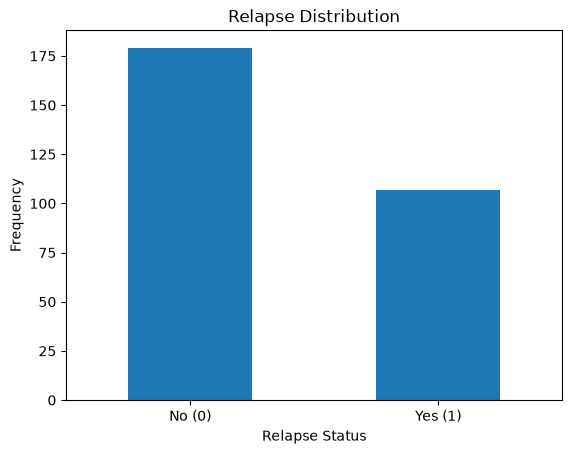

Relapse Count Relapse
0    179
1    107
Name: count, dtype: int64
Relapse Percentage Relapse
0    62.587413
1    37.412587
Name: count, dtype: float64


In [20]:
'''Distribution of how many patients relapsed versus relapse free'''
relapse_counts = clinical_parameters_df['Relapse'].value_counts()

'''Plotting and customizing the look of the plot'''
relapse_counts.plot(kind='bar', rot=0)
plt.title('Relapse Distribution')
plt.xlabel('Relapse Status')
plt.ylabel('Frequency')
plt.xticks([0, 1], ['No (0)', 'Yes (1)'])
plt.show()
#print (relapse_counts)

'''Showcasing the Raw values of relapse and relapse free, and % of dataset they make up'''
relapse_percentage = ((relapse_counts / len(clinical_parameters_df)) * 100)
print("Relapse Count", relapse_counts)
print("Relapse Percentage", relapse_percentage)


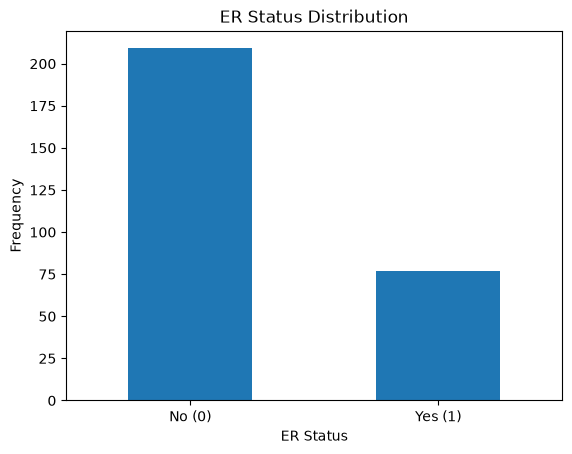

Relapse Count ER_status
ER+    209
ER-     77
Name: count, dtype: int64
Relapse Percentage ER_status
ER+    73.076923
ER-    26.923077
Name: count, dtype: float64


In [21]:
'''Distribution of ER Status'''
ER_counts = clinical_parameters_df['ER_status'].value_counts()

'''Plotting and customizing the look of the plot'''
ER_counts.plot(kind='bar', rot=0)
plt.title('ER Status Distribution')
plt.xlabel('ER Status')
plt.ylabel('Frequency')
plt.xticks([0, 1], ['No (0)', 'Yes (1)'])
plt.show()


'''Showcasing the Raw values of relapse and relapse free, and % of dataset they make up'''
ER_percentage = ((ER_counts / len(clinical_parameters_df)) * 100)
print("Relapse Count", ER_counts)
print("Relapse Percentage", ER_percentage)

###Bivariate Analysis

In [22]:
#contingency table, how many ER- samples relapsed versus didn't relapse, and how many ER+ samples relapsed versus didn't relapse.
pd.crosstab(clinical_parameters_df['ER_status'], clinical_parameters_df['Relapse'])

Relapse,0,1
ER_status,,
ER+,129,80
ER-,50,27


In [23]:
#check statistical significance using chi-square
from scipy.stats import chi2_contingency
chi_table = pd.crosstab(clinical_parameters_df['ER_status'], clinical_parameters_df['Relapse'])

chi2, p_value, dof, expected = chi2_contingency(chi_table)

print ('Chi-square statistics:', round(chi2,2))
print ('P-value:', round(p_value,2))

Chi-square statistics: 0.13
P-value: 0.72


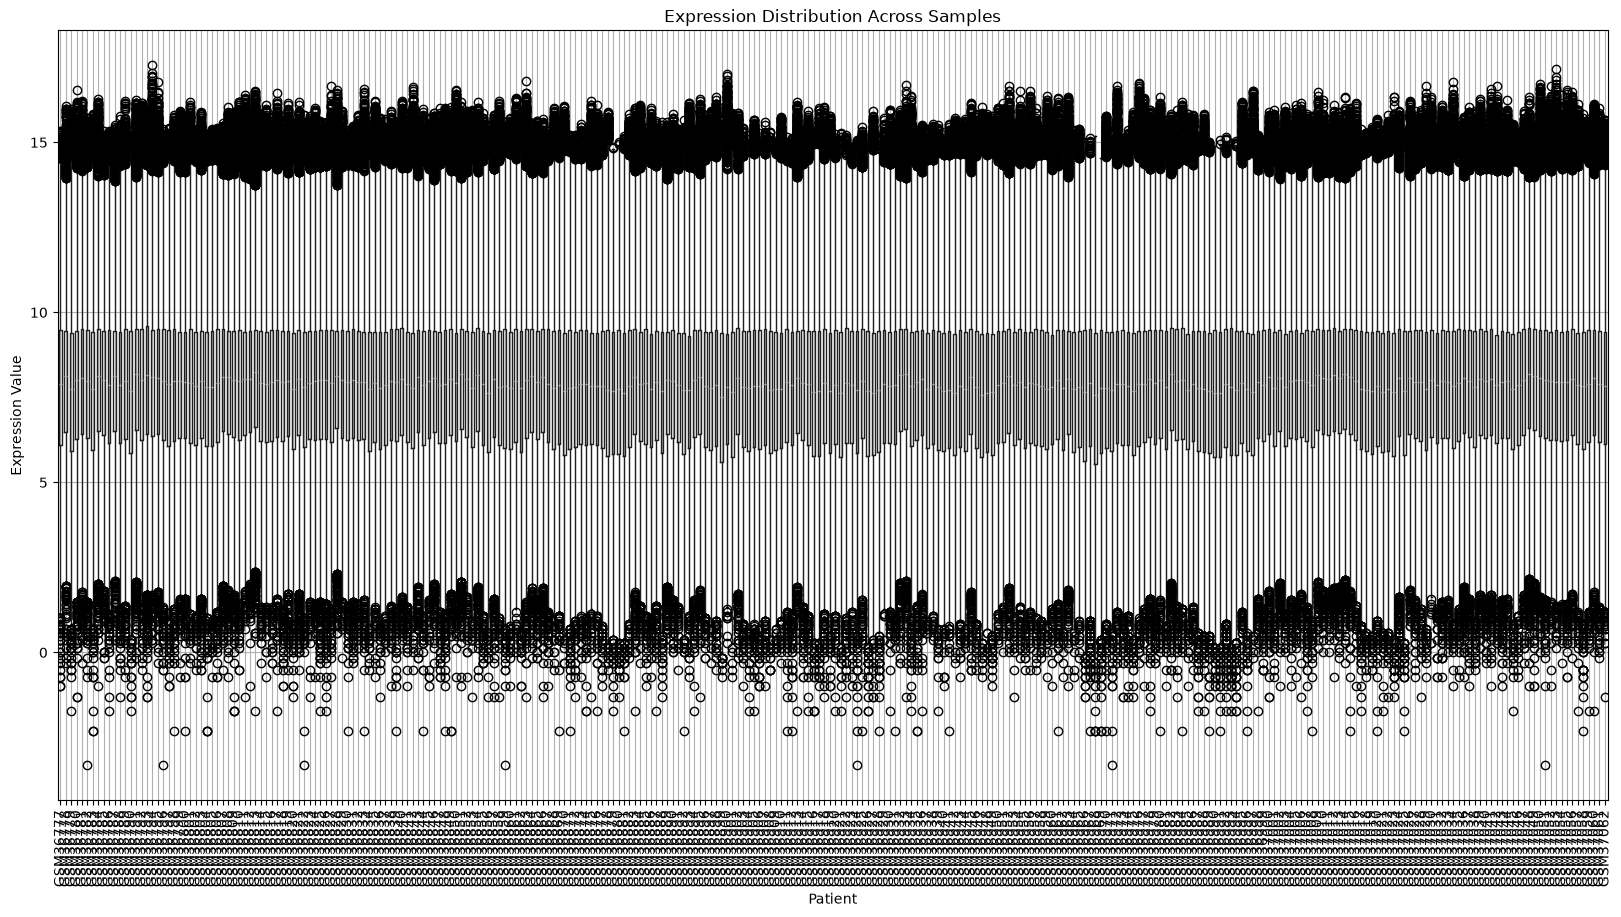

In [24]:
'''Expression Matrix Distribution- Box Plot'''
import matplotlib.pyplot as plt

gene_seq_df.boxplot(figsize=(20,10))
plt.xticks(rotation=90)
plt.ylabel("Expression Value")
plt.xlabel("Patient")
plt.title("Expression Distribution Across Samples")

plt.show()

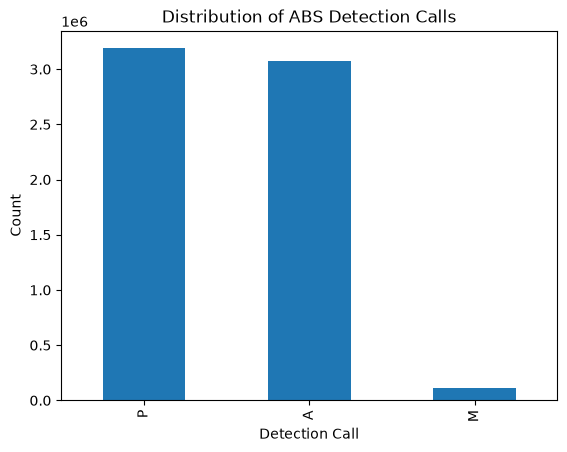


 Number of values by Type:
 P    3187954
A    3076782
M     108202
Name: count, dtype: int64

 Percentage of detections marked Present:

P: 50.02 %
A: 48.28 %
M: 1.7 %


In [25]:
'''ABS Detection Distribution'''
#Distribution of how many values are marked Present vs Absent vs Marginal
PAM_values = PAM_data_df.iloc[:,1:]

call_counts=PAM_values.stack().value_counts()

call_counts.plot(kind='bar')
plt.xticks(rotation=90)
plt.ylabel("Count")
plt.xlabel("Detection Call")
plt.title("Distribution of ABS Detection Calls")

plt.show()

'''Distributions by Number'''
p_percent = round((call_counts.get('P',0)/ PAM_values.size)*100, 2)
a_percent = round((call_counts.get('A',0)/ PAM_values.size)*100, 2)
m_percent = round((call_counts.get('M',0)/ PAM_values.size)*100, 2)

print ('\n Number of values by Type:\n', call_counts)
print ('\n Percentage of detections marked Present:\n')
print ('P:', p_percent, '%')
print ('A:', a_percent, '%')
print ('M:', m_percent, '%')


In [26]:
''' How many ProbeID rows are CONSISTENTLY marked Present'''
pam_value_row = PAM_data_df.iloc[:,1:]

#how many samples in each row are marked present. The output will be a value
#between 0 to 1. 0 = no values in the row marked present
# 1 = all values in the row not marked present

present_detection_rate = (pam_value_row == 'P').mean(axis = 1)

#summarizing

present_detection_summary = pd.DataFrame ( {
    'ID_REF': PAM_data_df.iloc[:,0],
    'Detection_Rate' : present_detection_rate.values
})


print (present_detection_summary)

#print (p_value_row.shape, p_value_row.dtypes.value_counts())

               ID_REF  Detection_Rate
0      AFFX-BioB-5_at        1.000000
1      AFFX-BioB-M_at        1.000000
2      AFFX-BioB-3_at        1.000000
3      AFFX-BioC-5_at        1.000000
4      AFFX-BioC-3_at        1.000000
...               ...             ...
22278     222380_s_at        0.996503
22279       222381_at        0.062937
22280     222382_x_at        0.300699
22281     222383_s_at        0.003497
22282       222384_at        0.000000

[22283 rows x 2 columns]


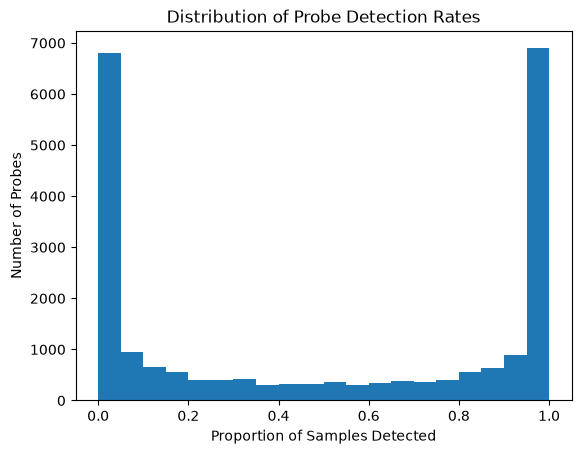

In [27]:
'''Visualizing detection rates in histogram'''

plt.hist(present_detection_summary['Detection_Rate'], bins =20)

plt.ylabel("Number of Probes")
plt.xlabel("Proportion of Samples Detected")
plt.title("Distribution of Probe Detection Rates")

plt.show()


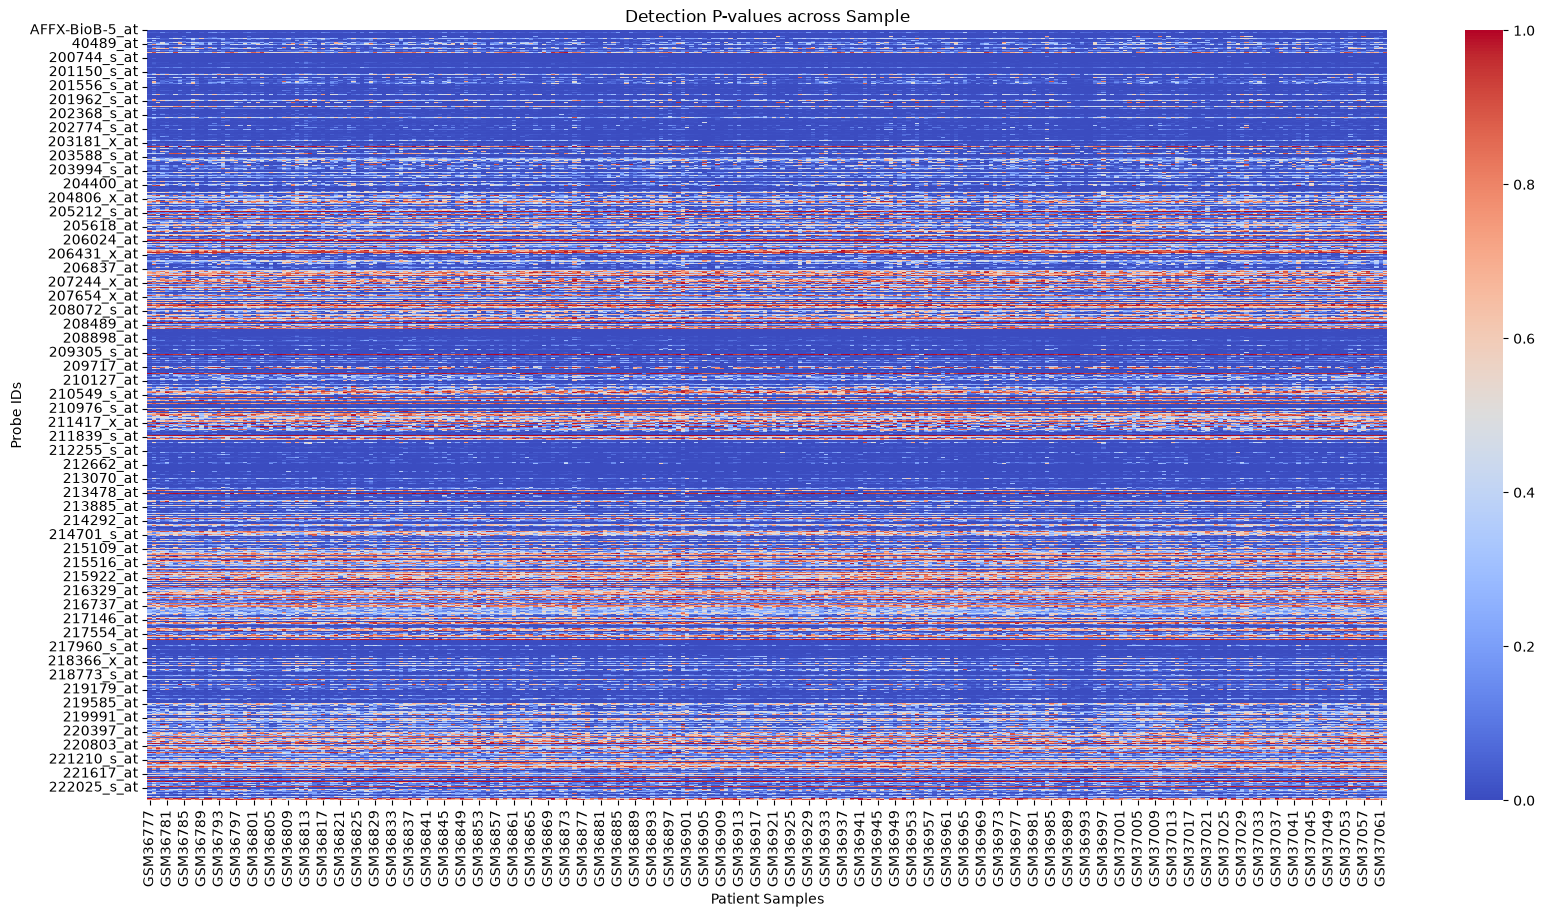

In [28]:
'''P-value Distribution'''
#Using a heat map will allow for easy spotting of probe IDs that are
#reliably meeting the p-value threshold, and ones that are not meeting
#the p-value threshold.

import seaborn as sns

P_values = P_data_df.set_index('ID_REF')

#sample_probes = P_values.sample(n=100, random_state=42)
plt.figure(figsize=(20,10))

sns.heatmap(
    P_values,
    cmap='coolwarm',
    vmin=0,
    vmax=1
)

plt.ylabel("Probe IDs")
plt.xlabel("Patient Samples")
plt.title("Detection P-values across Sample")

plt.show()

In [29]:
''' How many Probes are CONSISTENTLY 'reliable' at detecting signal'''
p_value_row = P_data_df.iloc[:,1:]

#how many samples in each row met the threshold. The output will be a value
#between 0 to 1. 0 = no values in the row meet the threshold
# 1 = all values in the row meet the threshold

detection_rate = (p_value_row < 0.05).mean(axis = 1)

#summarizing

detection_summary = pd.DataFrame ( {
    'ID_REF': P_data_df.iloc[:,0],
    'Detection_Rate' : detection_rate.values
})

print (detection_summary)

print (p_value_row.shape, p_value_row.dtypes.value_counts())

               ID_REF  Detection_Rate
0      AFFX-BioB-5_at        1.000000
1      AFFX-BioB-M_at        1.000000
2      AFFX-BioB-3_at        1.000000
3      AFFX-BioC-5_at        1.000000
4      AFFX-BioC-3_at        1.000000
...               ...             ...
22278     222380_s_at        0.996503
22279       222381_at        0.062937
22280     222382_x_at        0.300699
22281     222383_s_at        0.003497
22282       222384_at        0.000000

[22283 rows x 2 columns]
(22283, 286) float64    286
Name: count, dtype: int64


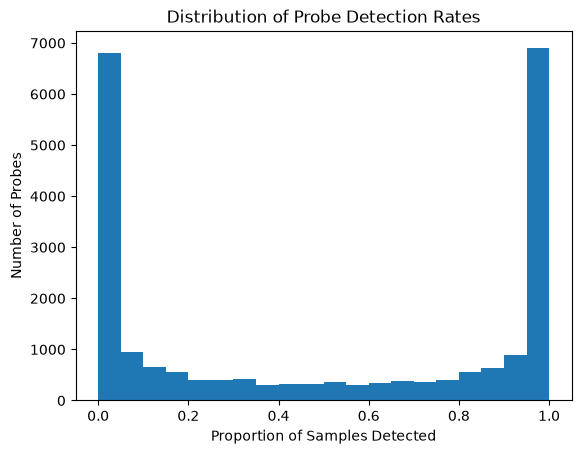

In [30]:
'''Visualizing detection rates in histogram'''

plt.hist(detection_summary['Detection_Rate'], bins =20)

plt.ylabel("Number of Probes")
plt.xlabel("Proportion of Samples Detected")
plt.title("Distribution of Probe Detection Rates")

plt.show()

## Step 3. Filtering Unreliable ProbeIDs
We have a distribution of how proportionally reliable each ProbeID is. The next step is filtering out the probeIDs that produce very weak/unrealible signals. There are various methodologies for filtering the low signal ProbeIDs. One paper cited success in filtering out ProbeIDs that have less than 50% 'Present' marked values in the row. I will employ this method for the ABS data, and also for the p-value data. And compare the results.

##Results

Both filtering methods had the same result. Both filtered down to 11,130 rows. This is consistent with what was shown in the previous analysis, where it seems the data was split almost in half, with half the Probes appearing to show strong signal, the other half appearing to show very weak signal.

In [31]:
'''Filter out ProbeIDs that have a detection rate of less than 0.5 from PAM'''

filtered_present_detection_df = present_detection_summary.loc[present_detection_summary['Detection_Rate'] >= 0.5, ['ID_REF', 'Detection_Rate']]

print (filtered_present_detection_df)

               ID_REF  Detection_Rate
0      AFFX-BioB-5_at        1.000000
1      AFFX-BioB-M_at        1.000000
2      AFFX-BioB-3_at        1.000000
3      AFFX-BioC-5_at        1.000000
4      AFFX-BioC-3_at        1.000000
...               ...             ...
22268     222370_x_at        0.905594
22269       222371_at        0.849650
22274       222376_at        0.856643
22277       222379_at        0.667832
22278     222380_s_at        0.996503

[11130 rows x 2 columns]


In [32]:
'''Filter out ProbeIDs that have a detection rate of less than 0.5 from P-value'''

filtered_p_detection_df = detection_summary.loc[detection_summary['Detection_Rate'] >= 0.5, ['ID_REF', 'Detection_Rate']]

print (filtered_p_detection_df)

               ID_REF  Detection_Rate
0      AFFX-BioB-5_at        1.000000
1      AFFX-BioB-M_at        1.000000
2      AFFX-BioB-3_at        1.000000
3      AFFX-BioC-5_at        1.000000
4      AFFX-BioC-3_at        1.000000
...               ...             ...
22268     222370_x_at        0.905594
22269       222371_at        0.849650
22274       222376_at        0.856643
22277       222379_at        0.667832
22278     222380_s_at        0.996503

[11130 rows x 2 columns]


In [33]:
'''Comparing resulting dataframes'''

print (filtered_present_detection_df.equals(filtered_p_detection_df))

True


In [34]:
'''Getting a list of the ProbeIDs that are significant enough to keep'''

probes_to_keep = filtered_present_detection_df['ID_REF']

In [35]:
filtered_expression_df = gene_seq_df[gene_seq_df['ID_REF'].isin(probes_to_keep)]

print (filtered_expression_df)

               ID_REF   GSM36777   GSM36778   GSM36779   GSM36780   GSM36781  \
0      AFFX-BioB-5_at   8.869440   9.558421   9.938697   9.812498   9.511950   
1      AFFX-BioB-M_at   9.845176  10.700266  11.032115  10.759722  10.636896   
2      AFFX-BioB-3_at   8.871289   9.960436  10.007448   9.824641   9.315150   
3      AFFX-BioC-5_at  10.421118  11.294104  11.398583  11.428831  11.075747   
4      AFFX-BioC-3_at  10.033698  10.914908  10.922882  10.695402  10.710720   
...               ...        ...        ...        ...        ...        ...   
22268     222370_x_at   7.238405   7.943687   7.212375   7.583459   8.269127   
22269       222371_at   7.632268   8.445843   6.378512   7.176921   8.316508   
22274       222376_at   7.723832   8.229780   8.075212   7.994919   8.199672   
22277       222379_at   9.786923   9.744498  12.414527   6.933100   6.432959   
22278     222380_s_at   8.724855  10.900791   7.541484   8.564531   9.504819   

        GSM36782   GSM36783   GSM36784 

##Step 4: Mapping the datasets
The original methodology was going to include mapping the ProbeID to it's corresponding gene symbol. However, there are several ProbeIDs that are missing annotation information, additionally some gene symbols may have multiple ProbeIDs. So instead it may be best to add in the gene symbols after feature selection

In [49]:
# the clinical parameters data is formatted differently
#than the gene expression data, where the sampleIDs are
#the rows in the clinical parameters data, versus
#sample IDs are the columns in the expression data.

print ('Rows and Columns of Expression data:', filtered_expression_df.shape)
print ('\nColumns of Expression data:\n', filtered_expression_df.columns [:5])

print ('Rows and Columns of clinical parameters data:',clinical_parameters_df.head())
print ('Columns of clinical parameters data:',clinical_parameters_df.columns)

Rows and Columns of Expression data: (11130, 287)

Columns of Expression data:
 Index(['ID_REF', 'GSM36777', 'GSM36778', 'GSM36779', 'GSM36780'], dtype='object')
Rows and Columns of clinical parameters data:    PID Sample_Accession lymph node status  Follow_up_months  Relapse  \
0    3         GSM36793          negative               101        0   
1    5         GSM36796          negative               118        0   
2    6         GSM36797          negative                 9        1   
3    7         GSM36798          negative               106        0   
4    8         GSM36800          negative                37        1   

  ER_status  Brain relapses (1=yes, 0=no)  
0       ER-                             0  
1       ER+                             0  
2       ER-                             0  
3       ER-                             0  
4       ER-                             0  
Columns of clinical parameters data: Index(['PID', 'Sample_Accession', 'lymph node status', 'Fo

In [37]:
'''indexing and Transposing '''

expression_by_sample = filtered_expression_df.set_index('ID_REF').T

expression_by_sample.index.name = 'Sample_Accession'
expression_by_sample = expression_by_sample.reset_index()

print(expression_by_sample.shape)
print(expression_by_sample.head())

print (expression_by_sample['Sample_Accession'].isin(clinical_parameters_df['Sample_Accession']).sum())

print(expression_by_sample.columns[:5])
print(expression_by_sample.shape)

(286, 11131)
ID_REF Sample_Accession  AFFX-BioB-5_at  AFFX-BioB-M_at  AFFX-BioB-3_at  \
0              GSM36777        8.869440        9.845176        8.871289   
1              GSM36778        9.558421       10.700266        9.960436   
2              GSM36779        9.938697       11.032115       10.007448   
3              GSM36780        9.812498       10.759722        9.824641   
4              GSM36781        9.511950       10.636896        9.315150   

ID_REF  AFFX-BioC-5_at  AFFX-BioC-3_at  AFFX-BioDn-5_at  AFFX-BioDn-3_at  \
0            10.421118       10.033698        10.516389        12.921357   
1            11.294104       10.914908        11.228999        13.612592   
2            11.398583       10.922882        11.455533        13.798674   
3            11.428831       10.695402        11.146123        13.480879   
4            11.075747       10.710720        10.665247        13.449084   

ID_REF  AFFX-CreX-5_at  AFFX-CreX-3_at  ...  222360_at  222361_at  222366_at  \

In [53]:
'''Merging Clinical Parameters with the Expression Data'''

clinical_info = clinical_parameters_df[['Sample_Accession', 'Relapse', 'Follow_up_months','ER_status']]

#print (clinical_info)

final_expression_df = expression_by_sample.merge(clinical_info, on='Sample_Accession', how='inner', validate='one_to_one')

print(final_expression_df.shape)
print(final_expression_df[['Sample_Accession', 'Relapse', 'Follow_up_months','ER_status']].head())




(286, 11134)
  Sample_Accession  Relapse  Follow_up_months ER_status
0         GSM36777        0                79       ER+
1         GSM36778        1                50       ER+
2         GSM36779        0               132       ER+
3         GSM36780        0                84       ER-
4         GSM36781        0               147       ER+


In [56]:
#export to csv in case I want a copy of this. JK I don't want a copy of this anymore


final_expression_df.to_csv("../data/dashboard_dataset.csv", index=False)


## Analysis of Data

In [40]:
# Bivariate analysis of relapse groups
from scipy.stats import mannwhitneyu
import pandas as pd


relapse = final_expression_df[final_expression_df['Relapse'] == 1]
no_relapse = final_expression_df[final_expression_df['Relapse'] == 0]


gene_columns = final_expression_df.select_dtypes(
    include='number'
).columns.drop('Relapse')

results = []

for gene in gene_columns:

    group1 = relapse[gene].dropna()
    group0 = no_relapse[gene].dropna()

    stat, p_value = mannwhitneyu(
        group1,
        group0,
        alternative='two-sided'
    )

    results.append({
        'Probe_ID': gene,
        'Relapse_Median': group1.median(),
        'No_Relapse_Median': group0.median(),
        'P_value': p_value
    })

results_df = pd.DataFrame(results)

print(results_df.head())

         Probe_ID  Relapse_Median  No_Relapse_Median   P_value
0  AFFX-BioB-5_at        9.558421           9.616733  0.561468
1  AFFX-BioB-M_at       10.731149          10.667821  0.091684
2  AFFX-BioB-3_at        9.767026           9.707014  0.390244
3  AFFX-BioC-5_at       11.100794          11.054333  0.476365
4  AFFX-BioC-3_at       10.642503          10.664714  0.279457


In [41]:
# FDR correction for 11 k probes

from statsmodels.stats.multitest import multipletests


results_df['FDR'] = multipletests(
    results_df['P_value'],
    method='fdr_bh'
)[1]


results_df = results_df.sort_values('FDR')


#print(results_df.head(10))

# Count probes significant after FDR correction
significant_probes = results_df[results_df['FDR'] < 0.05]

print("Total probes tested:", len(results_df))
print("Significant probes:", len(significant_probes))
print("Percentage significant:",
      round(len(significant_probes) / len(results_df) * 100, 2), "%")

Total probes tested: 11130
Significant probes: 190
Percentage significant: 1.71 %


In [42]:
'''There are several missing gene symbols in the annotation data, we must figure out if any of these missing symbols will affect our final filtered data set'''

#gene_symbol_mapping = annotation_data_df [['ID', 'Gene Symbol']].copy()
#print ('Duplicated annotation IDs:', gene_symbol_mapping['ID'].duplicated().sum())
#print("Missing gene symbols:", gene_symbol_mapping['Gene Symbol'].isna().sum())
#print (gene_symbol_mapping.head())

gene_symbol_mapping = annotation_data_df.set_index('ID')['Gene Symbol'].to_dict()

annotated_expression = final_expression_df.copy()

gene_symbols = pd.Series ({
    col: gene_symbol_mapping.get(col, pd.NA)
    for col in final_expression_df.columns
     if col != 'Sample_Accession'},
    name='Gene Symbol'
)

print("Original shape:", final_expression_df.shape)
print("Number of probe columns:", len(gene_symbols))
print("Probes with missing symbols:", gene_symbols.isna().sum())
print("Probes with symbols:", gene_symbols.notna().sum())


Original shape: (286, 11133)
Number of probe columns: 11132
Probes with missing symbols: 173
Probes with symbols: 10959


## Feature Selection
We will be employing SVM-RFE for feature selection

In [43]:
'''Getting an understanding of the shape of our data and names of our columns so we can set up the SVM correctly'''
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

print("Dataset shape:", final_expression_df.shape)
print(final_expression_df.columns[:10].tolist())
print(final_expression_df["Relapse"].value_counts())
print("Missing values:", final_expression_df.isnull().sum().sum())

Dataset shape: (286, 11133)
['Sample_Accession', 'AFFX-BioB-5_at', 'AFFX-BioB-M_at', 'AFFX-BioB-3_at', 'AFFX-BioC-5_at', 'AFFX-BioC-3_at', 'AFFX-BioDn-5_at', 'AFFX-BioDn-3_at', 'AFFX-CreX-5_at', 'AFFX-CreX-3_at']
Relapse
0    179
1    107
Name: count, dtype: int64
Missing values: 0


In [44]:
'''Separating gene expression from outcome'''

X = final_expression_df.drop (columns=['Sample_Accession', 'Relapse', 'ER_status'])

y = final_expression_df['Relapse']

#just quick double check

print ("Features", X.shape)
print ("Outcome", y.shape)
print ("Outcome classes", y.value_counts())

Features (286, 11130)
Outcome (286,)
Outcome classes Relapse
0    179
1    107
Name: count, dtype: int64


In [ ]:
dashboard_df.to_csv("../data/dashboard_dataset.csv", index=False)

In [ ]:
from lifelines import KaplanMeierFitter
print(dashboard_df["Relapse"].value_counts())

print("\nFollow-up summary:")
print(dashboard_df["Follow_up_months"].describe())

Relapse
0    179
1    107
Name: count, dtype: int64

Follow-up summary:
count    286.000000
mean      77.520979
std       42.267958
min        2.000000
25%       37.000000
50%       86.000000
75%      108.000000
max      171.000000
Name: Follow_up_months, dtype: float64


In [ ]:
from lifelines import KaplanMeierFitter

# Initialize the Kaplan-Meier estimator
kmf = KaplanMeierFitter()

# Fit the survival model
kmf.fit(
    durations=dashboard_df["Follow_up_months"],
    event_observed=dashboard_df["Relapse"],
    label="Relapse-free survival"
)

# Display survival estimates
print(kmf.survival_function_.head(10))

          Relapse-free survival
timeline                       
0.0                    1.000000
2.0                    0.996503
5.0                    0.993007
6.0                    0.986014
7.0                    0.975524
8.0                    0.968531
9.0                    0.958042
11.0                   0.944056
12.0                   0.940559
13.0                   0.937063


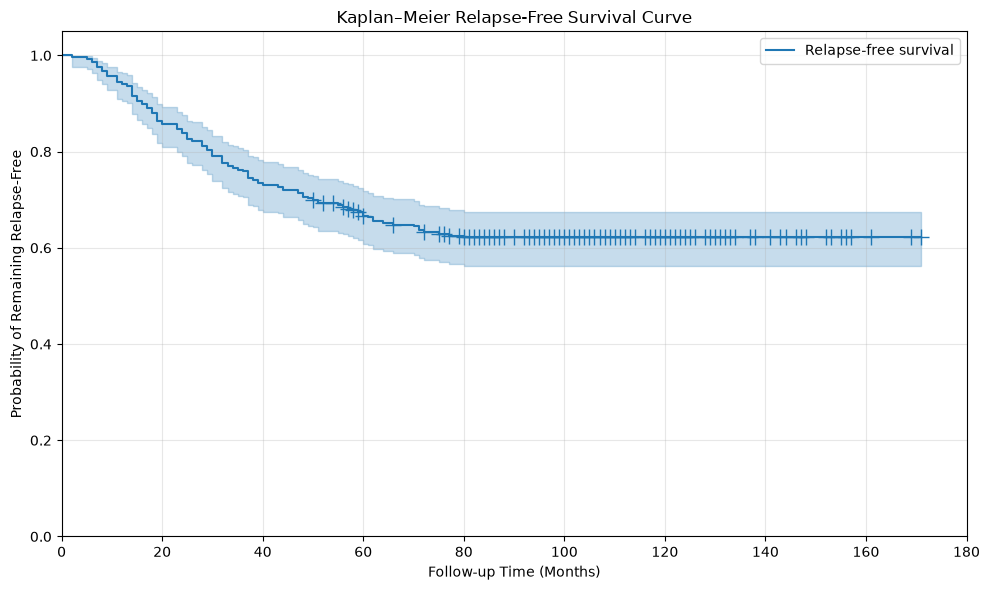

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

kmf.plot_survival_function(
    ci_show=True,
    show_censors=True
)

plt.title("Kaplan–Meier Relapse-Free Survival Curve")
plt.xlabel("Follow-up Time (Months)")
plt.ylabel("Probability of Remaining Relapse-Free")

plt.ylim(0, 1.05)
plt.xlim(0, 180)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Extract relapse-free survival estimates at selected time points
time_points = [36, 60, 84, 120]

survival_estimates = kmf.predict(time_points)

print("Relapse-Free Survival Estimates:")
print((survival_estimates * 100).round(2))

Relapse-Free Survival Estimates:
36     75.87
60     66.69
84     62.17
120    62.17
Name: Relapse-free survival, dtype: float64
